In [3]:
import torch

In [4]:
from grokkingexperiments.groups import generate_data
from grokkingexperiments.data import split_data
from grokkingexperiments.model import GrokkingModel
from grokkingexperiments.train import train_model
from grokkingexperiments.utils import plot_metrics

In [5]:
# Use gpu if its availble
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} to train the model")

Using cpu to train the model


Epoch  0      | Loss 4.184  | Test loss 4.192  | Train accuracy 0.017  | Test accuracy 0.012 
Epoch  100    | Loss 2.443  | Test loss 5.964  | Train accuracy 0.470  | Test accuracy 0.000 
Epoch  200    | Loss 0.657  | Test loss 8.950  | Train accuracy 0.996  | Test accuracy 0.000 
Epoch  300    | Loss 0.204  | Test loss 10.533 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  400    | Loss 0.129  | Test loss 10.793 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  500    | Loss 0.103  | Test loss 10.750 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  600    | Loss 0.088  | Test loss 10.655 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  700    | Loss 0.078  | Test loss 10.550 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  800    | Loss 0.070  | Test loss 10.459 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  900    | Loss 0.063  | Test loss 10.374 | Train accuracy 1.000  | Test accuracy 0.000 
Epoch  1000   | Loss 0.058  | Test loss 10.296 | Train accur

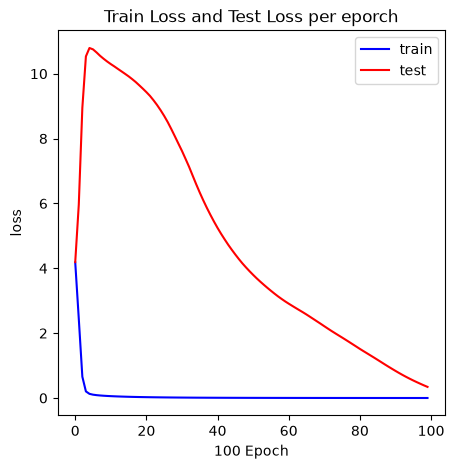

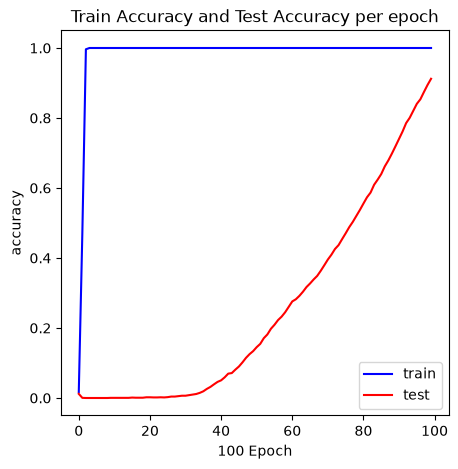

In [ ]:
N = 64
TRAIN_SPLIT = 0.4
EMBED_DIM = 64
HIDDEN_DIM = 128
epochs = 250_000

# Create an instance of the model
model = GrokkingModel(embed_dimension=EMBED_DIM, hidden_dimension=HIDDEN_DIM, n=N)

# Generate our data and split it
data = generate_data(n=N, op="mod_n")
x_train, y_train, x_test, y_test = split_data(data, split = TRAIN_SPLIT)


# Put the model and data on the correct device
x_train = x_train.to(device)
y_train = y_train.to(device)
x_test = x_test.to(device)
y_test = y_test.to(device)

# Train the model, and store the four training metric histories in `metrics`
metrics = train_model(epochs, model, x_train, y_train, x_test, y_test)

# Unpack the metrics
training_losses = metrics[0]
test_losses = metrics[1]
training_accuracies = metrics[2]
test_accuracies = metrics[3]

# Plot the metrics 
plot_metrics(training_losses, test_losses, 'Train Loss and Test Loss per eporch', 'loss')
plot_metrics(training_accuracies, test_accuracies, 'Train Accuracy and Test Accuracy per epoch', 'accuracy')
